# ATLAS INSIGHT — Data Analyst AI | NHÓM 12
## Stage 1: Thu thập, tích hợp, lưu trữ và EDA | Stage 2: PCA, K-Means, Regression, Classification và Gradio UI

**Dữ liệu nền của mô hình:** Gapminder 1952–2007, **1.704** quan sát quốc gia–năm thuộc **142** quốc gia.

**Đối chiếu hai nguồn thực:** Gapminder (1.704 dòng) và World Bank (1.400 dòng) được chuẩn hóa, nối dọc thành **3.104 dòng theo nguồn**, nhưng chỉ có **1.704 khóa quốc gia–năm duy nhất**. Bảng này phục vụ *kiểm tra nguồn, tích hợp và đánh giá sự khác biệt*, **không phải** tập huấn luyện 3.104 mẫu độc lập.

**Các biến `sim_*` là dữ liệu mô phỏng**, không phải chỉ tiêu y tế, giáo dục hay chính sách chính thức. Dự đoán chỉ minh họa phương pháp trên dữ liệu lịch sử, không phải dự báo hiện hành hoặc kết luận nhân quả.

**Nguồn chính:** https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv  
**Nguồn đối chiếu:** https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN?format=json&per_page=20000

**Hướng dẫn chạy:** Mở Notebook từ thư mục project, cài `requirements.txt`, chạy lần lượt từ trên xuống. Mã gọi các script trong `src/`; dữ liệu và các ảnh đã lưu ở `data/`, `charts/`, `reports/`, `screenshots/`.

In [1]:
# ORIGINAL DATASET URL: https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv
from pathlib import Path
import sys,subprocess,json
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=Path.cwd() if (Path.cwd()/'src').is_dir() else Path.cwd().parent
print('Project root:',ROOT)
print('Public dataset URL: https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv')

Project root: f:\Final Project AI\NHOM_12_FINAL_PROJECT\AI_Data_Analyst_Project
Public dataset URL: https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv


## PHẦN I — STAGE 1: THU THẬP, TÍCH HỢP VÀ LÀM SẠCH
### 1. Dữ liệu Gapminder nền + dữ liệu động mô phỏng

- `src/01_prepare_data.py`: lấy bản Gapminder lịch sử (1.704 dòng), chia thành 2 **nhóm địa lý của cùng nguồn**, chuẩn hóa tên/kiểu cột và `pd.concat` thành 1.704 dòng. Hai nhóm này **không phải hai nhà cung cấp độc lập**.
- Tạo 3 chỉ số số và 1 chỉ số phân loại **mô phỏng** bằng NumPy; cố ý đưa vào 375 ô thiếu để trình diễn làm sạch.
- `pd.merge(..., how='left')` theo khóa `record_id` giữ đầy đủ 1.704 dòng thật; dữ liệu mô phỏng được gắn riêng theo cùng khóa.
- Phần **World Bank như nguồn độc lập để so sánh** được kiểm chứng trong mục bổ sung ngay trước Stage 2. Tránh cộng 3.104 dòng thành số quan sát độc lập khi huấn luyện AI.

In [2]:

import subprocess
import sys

print("Python:", sys.executable)
print("Project:", ROOT)

result = subprocess.run(
    [sys.executable, str(ROOT / "src/01_prepare_data.py")],
    cwd=ROOT,
    capture_output=True,
    text=True
)

print("EXIT CODE:", result.returncode)
print("\n=== OUTPUT ===")
print(result.stdout)
print("\n=== ERROR DETAILS ===")
print(result.stderr)
if result.returncode != 0:
    raise RuntimeError('01_prepare_data.py chạy lỗi; xem ERROR DETAILS ở trên')
a=pd.read_csv(ROOT/'data/raw/Feed_A_Africa_Asia.csv')
b=pd.read_csv(ROOT/'data/raw/Feed_B_Other_Regions.csv')
sim=pd.read_csv(ROOT/'data/synthetic/simulated_country_year_indicators.csv')
master=pd.read_csv(ROOT/'data/processed/master_sparse.csv')
print('Feed sizes:',len(a),len(b),'| Synthetic:',len(sim),'| Left-merged:',len(master))
display(master.head(5))

Python: c:\Python311\python.exe
Project: f:\Final Project AI\NHOM_12_FINAL_PROJECT\AI_Data_Analyst_Project
EXIT CODE: 0

=== OUTPUT ===
Real source: 1704 | feed A: 1020 | feed B: 684
Merged: (1704, 16) | synthetic missing: 375


=== ERROR DETAILS ===

Feed sizes: 1020 684 | Synthetic: 1704 | Left-merged: 1704


,continent,country,data_feed,gdp_per_capita,iso_alpha,iso_num,life_expectancy,population,year,record_id,sim_health_index,sim_education_index,sim_trend_index,sim_policy_group,synthetic_record,target_high_life_expectancy
0,Asia,Afghanistan,Feed_A_Africa_Asia,779.445314,AFG,4,28.801,8425333.0,1952,Afghanistan_1952,67.49,47.37,27.24,Moderate simulated investment,True,0
1,Asia,Afghanistan,Feed_A_Africa_Asia,820.853030,AFG,4,30.332,9240934.0,1957,Afghanistan_1957,66.00,60.59,60.47,Moderate simulated investment,True,0
2,Asia,Afghanistan,Feed_A_Africa_Asia,853.100710,AFG,4,31.997,10267083.0,1962,Afghanistan_1962,62.15,61.94,60.91,Moderate simulated investment,True,0
3,Asia,Afghanistan,Feed_A_Africa_Asia,836.197138,AFG,4,34.020,11537966.0,1967,Afghanistan_1967,54.96,67.27,54.73,Moderate simulated investment,True,0
4,Asia,Afghanistan,Feed_A_Africa_Asia,739.981106,AFG,4,36.088,13079460.0,1972,Afghanistan_1972,48.58,NaN,51.25,Lower simulated investment,True,0


### 2. SQLite Storage → Data Retrieval → Cleaning & EDA

Thực hiện `master_sparse.to_sql`, đọc `SELECT *`, gán thiếu theo median theo châu lục, Unknown cho category, ffill/bfill trong từng chuỗi quốc gia. Xuất các bảng thống kê mô tả mean/median/std/skew/kurt và IQR.

In [3]:
subprocess.run([sys.executable,str(ROOT/'src/02_storage_clean_eda.py')],cwd=ROOT,check=True)
miss=pd.read_csv(ROOT/'reports/missingness_before.csv')
clean=pd.read_csv(ROOT/'data/processed/master_clean.csv')
print('Missing before:',miss.missing_count.sum(),'| after:',clean.isna().sum().sum())
display(pd.read_csv(ROOT/'reports/imputation_impact.csv'))
display(pd.read_csv(ROOT/'reports/univariate_statistics.csv').head())

Missing before: 375 | after: 0


,column,n_before,mean_before,mean_after,median_before,median_after,std_before,std_after,mean_change_percent
0,sim_health_index,1610,71.9514,71.8875,71.975,71.670,14.2393,13.8906,-0.0888
1,sim_education_index,1585,72.5367,72.5025,72.780,72.465,13.6799,13.3037,-0.0472
2,sim_trend_index,1627,73.9435,73.8096,73.620,73.515,12.9771,13.0496,-0.1810


,Unnamed: 0,mean,median,std,skew,kurt
0,life_expectancy,5.947444e+01,6.071250e+01,1.291711e+01,-0.252702,-1.126685
1,gdp_per_capita,7.215327e+03,3.531847e+03,9.857455e+03,3.850272,27.515894
2,population,2.960121e+07,7.023596e+06,1.061579e+08,8.340218,77.948203
3,sim_health_index,7.188751e+01,7.167000e+01,1.389063e+01,-0.083126,-0.429492
4,sim_education_index,7.250249e+01,7.246500e+01,1.330374e+01,-0.028616,-0.440416


### 3. EDA: tối thiểu 5 biểu đồ + giải thích “So What?”

#### 01 missingness

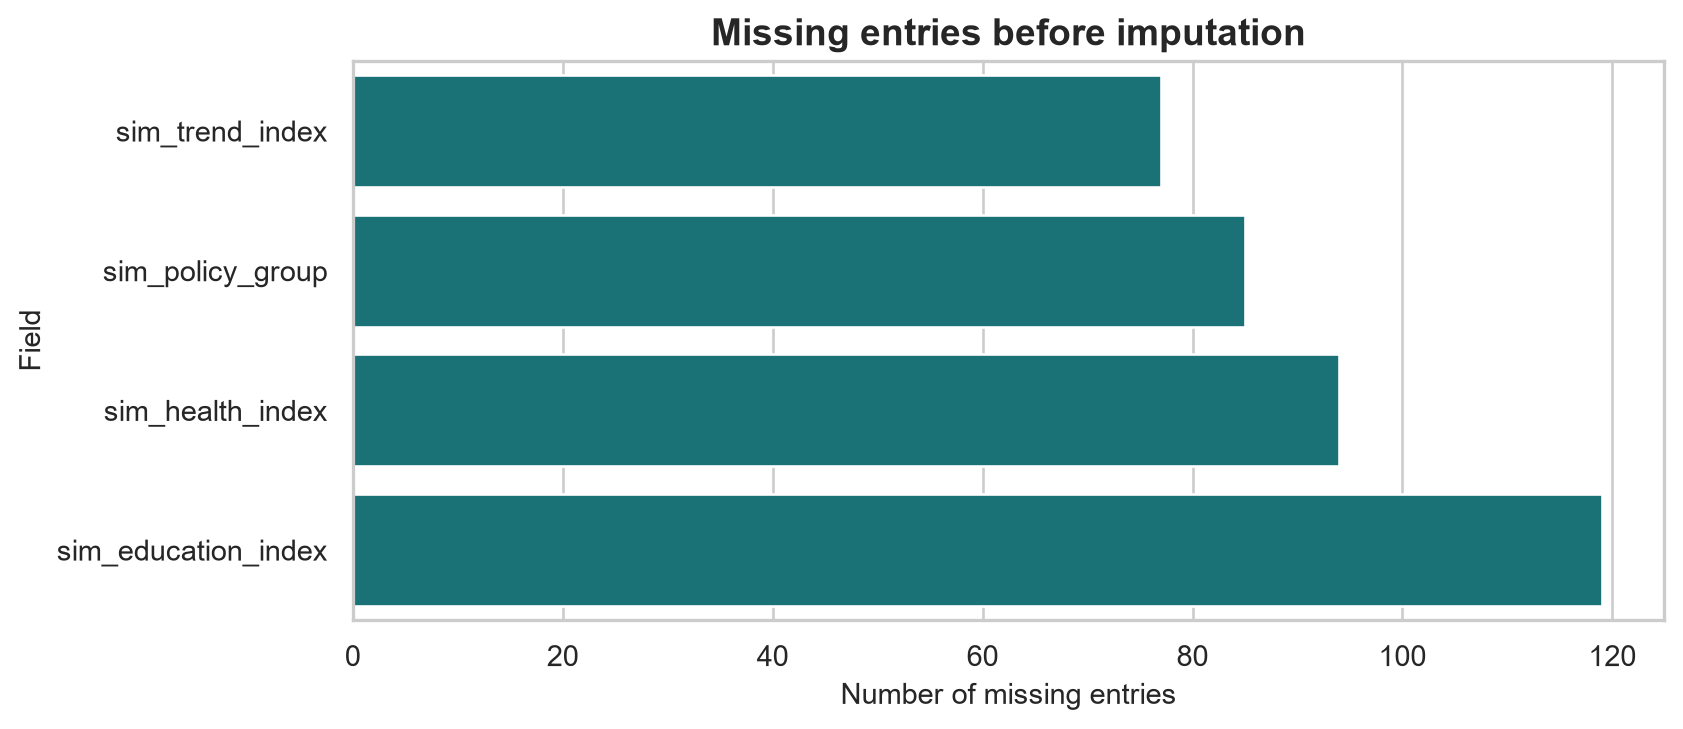

In [4]:
display(Image(filename=str(ROOT/"charts/01_missingness.png"),width=760))

**SO WHAT?** Dataset nền có **375 ô thiếu**, đều nằm trong các cột mô phỏng (`sim_*`); các chỉ tiêu quan sát thật không bị làm rỗng. Nếu loại bỏ mọi dòng thiếu, mẫu lịch sử có nguy cơ mất tính đại diện. Nhóm chọn bù thiếu theo loại biến và giữ đủ 1.704 quan sát phục vụ đánh giá.

#### 02 imputation distribution

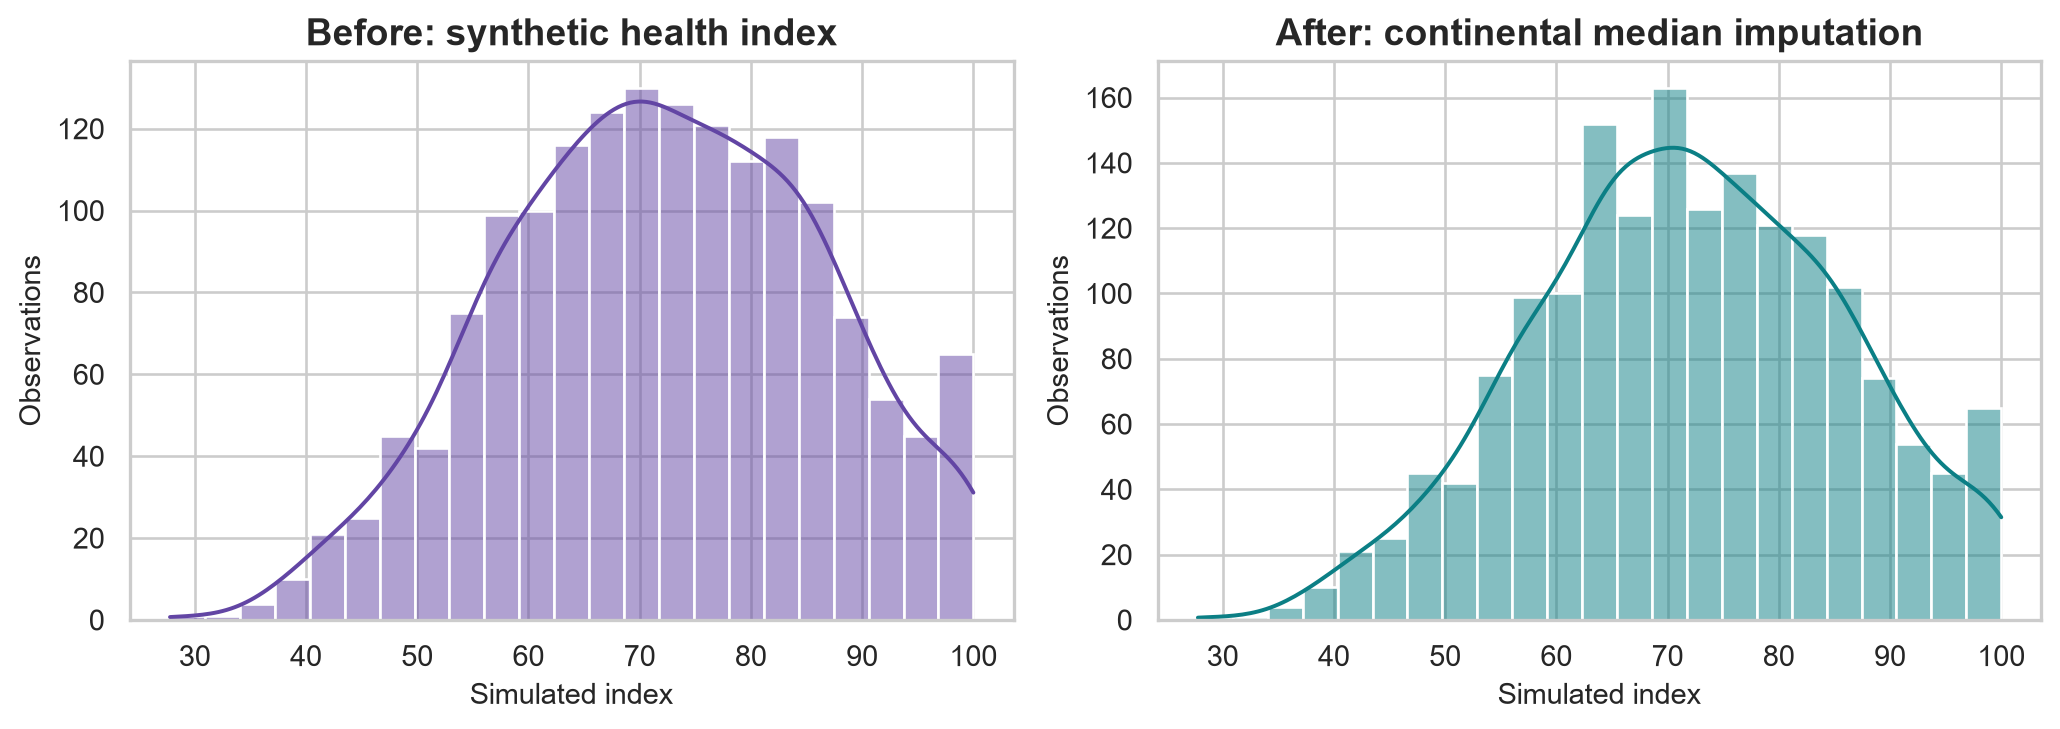

In [5]:
display(Image(filename=str(ROOT/"charts/02_imputation_distribution.png"),width=760))

**SO WHAT?** Bù trung vị theo châu lục giúp hạn chế ảnh hưởng các giá trị cực đoan. Sau bù thiếu, trung bình `sim_health_index` thay đổi khoảng **−0,09%**, giáo dục **−0,05%**; độ lệch chuẩn có thể giảm vì thêm giá trị gần tâm phân phối. Các chỉ số này là mô phỏng nên chỉ dùng để đánh giá quy trình, **không phải bằng chứng về chất lượng y tế/giáo dục thật**.

#### 03 life expectancy hist kde

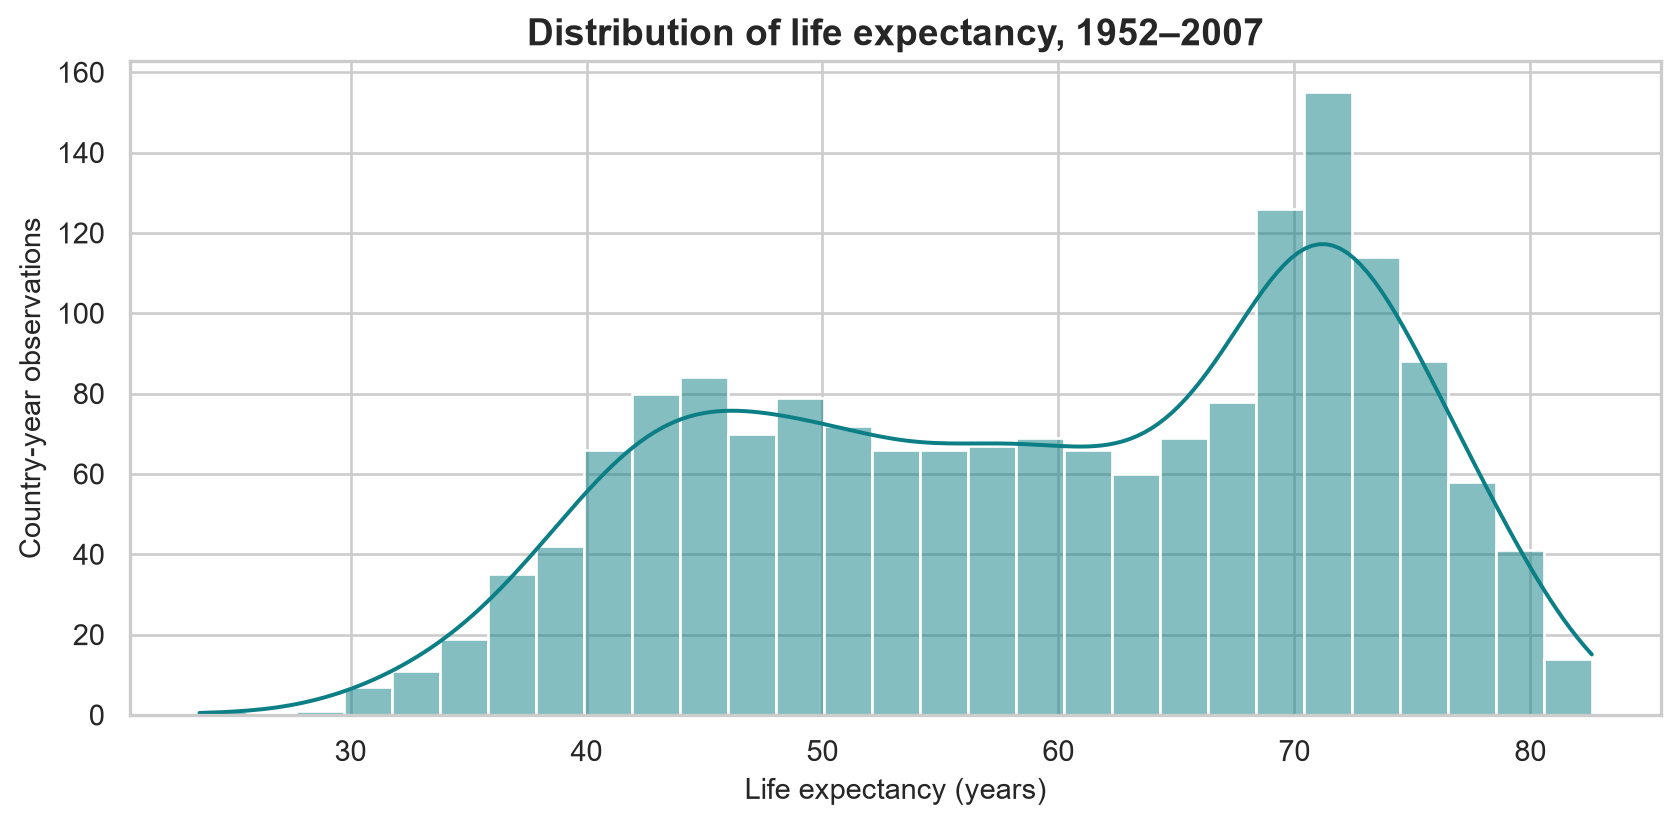

In [6]:
display(Image(filename=str(ROOT/"charts/03_life_expectancy_hist_kde.png"),width=760))

**SO WHAT?** Tuổi thọ trung bình toàn bộ quan sát **59,47 năm**, trung vị khoảng **60,71 năm**. Đây là dữ liệu **1952–2007** với cùng quốc gia lặp theo năm; không đại diện tuổi thọ quốc gia hiện nay. Phân phối trải rộng, vì vậy chỉ dùng một thống kê trung tâm không đủ; cần kết hợp năm, kinh tế, châu lục và các phép đánh giá trên quốc gia chưa thấy.

#### 04 life expectancy box iqr

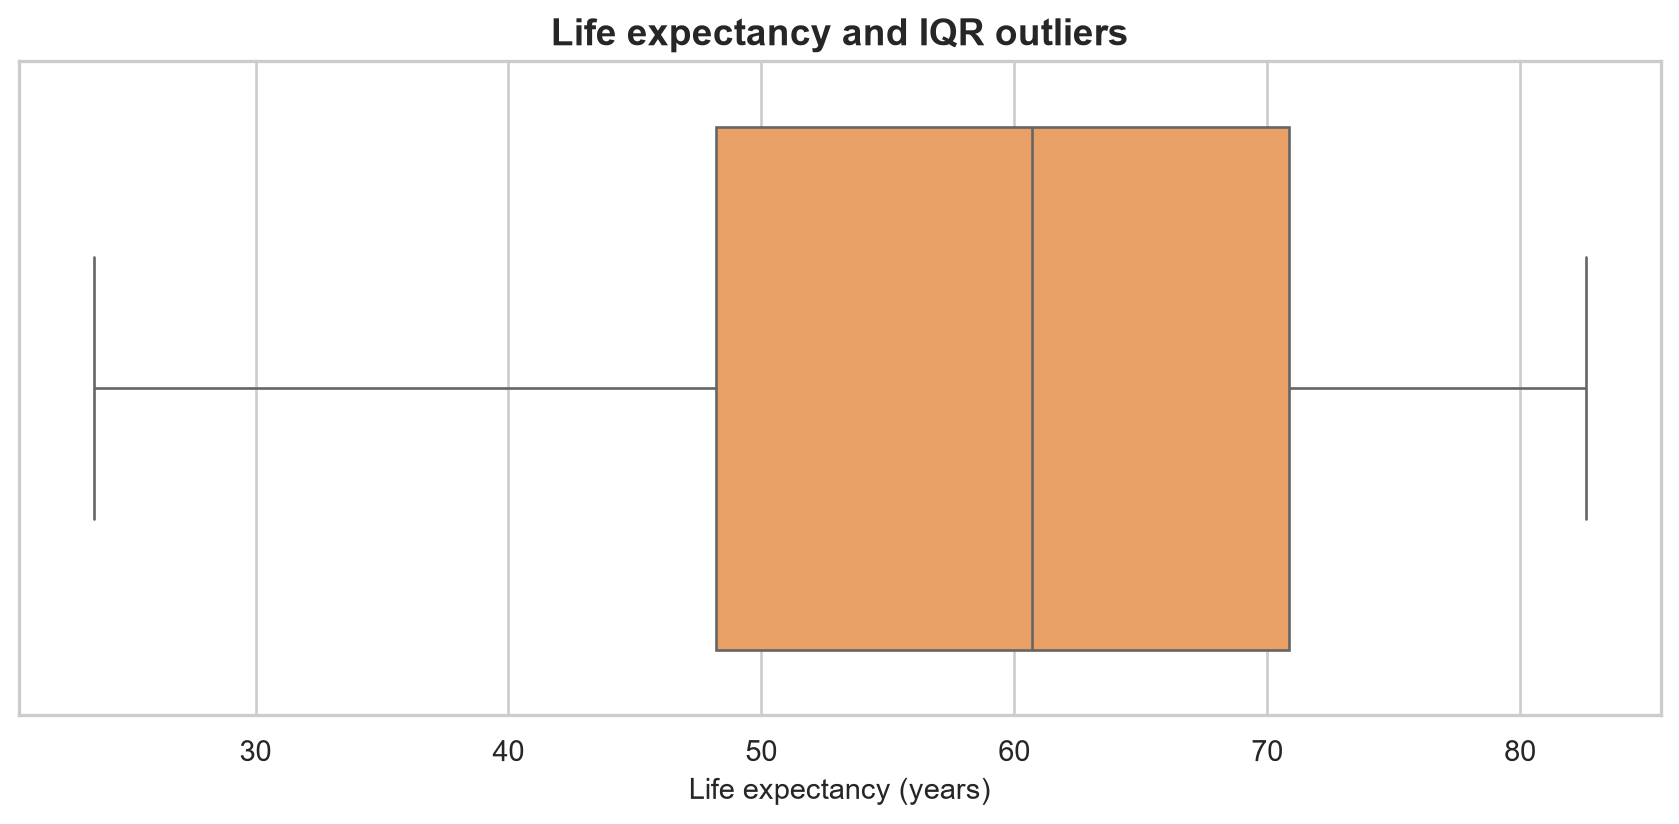

In [7]:
display(Image(filename=str(ROOT/"charts/04_life_expectancy_box_iqr.png"),width=760))

**SO WHAT?** Theo IQR, tuổi thọ không có ngoại lai được đánh dấu, nhưng GDP/người có **143** và dân số có **208** quan sát nằm ngoài hàng rào IQR. Không xóa các bản ghi kinh tế/dân số lớn chỉ vì chúng khác biệt; dùng `log1p` cho GDP và dân số trước hồi quy và so sánh kết quả trên tập kiểm tra độc lập.

#### 05 continent bar

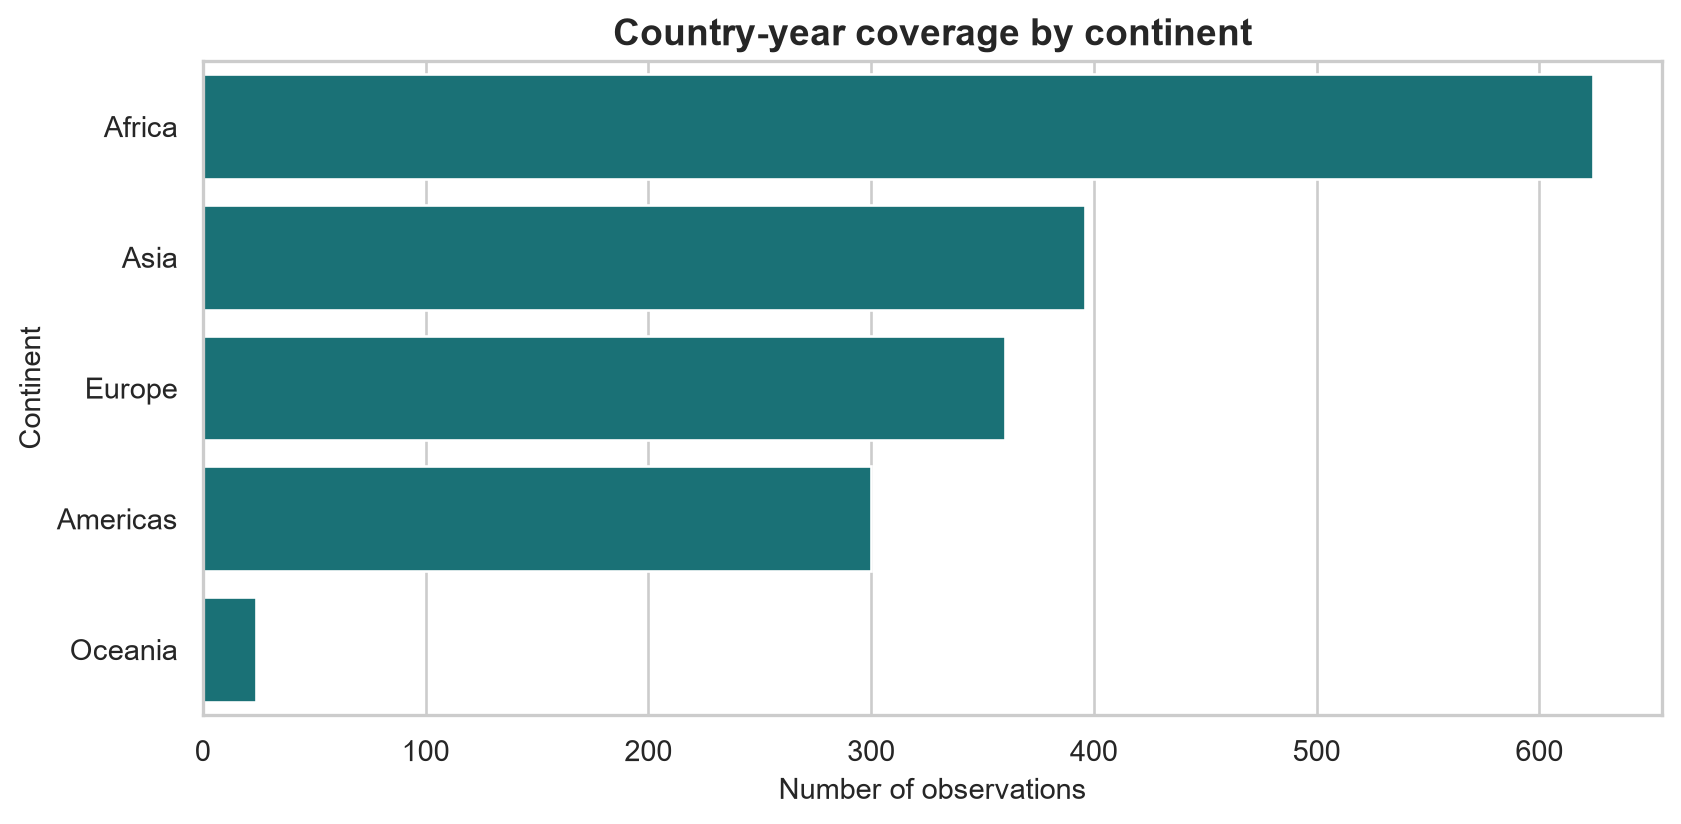

In [8]:
display(Image(filename=str(ROOT/"charts/05_continent_bar.png"),width=760))

**SO WHAT?** Phân bố dữ liệu không đồng đều: Africa **624** quan sát, Oceania **24**. Vì mẫu nhỏ ở một số châu lục, không suy rộng hiệu quả mô hình từ độ chính xác toàn cục sang mọi khu vực. Châu lục được mã hóa bằng `OneHotEncoder`, đồng thời nên báo cáo sai số theo châu lục nếu nghiên cứu được mở rộng.

#### 06 correlation heatmap

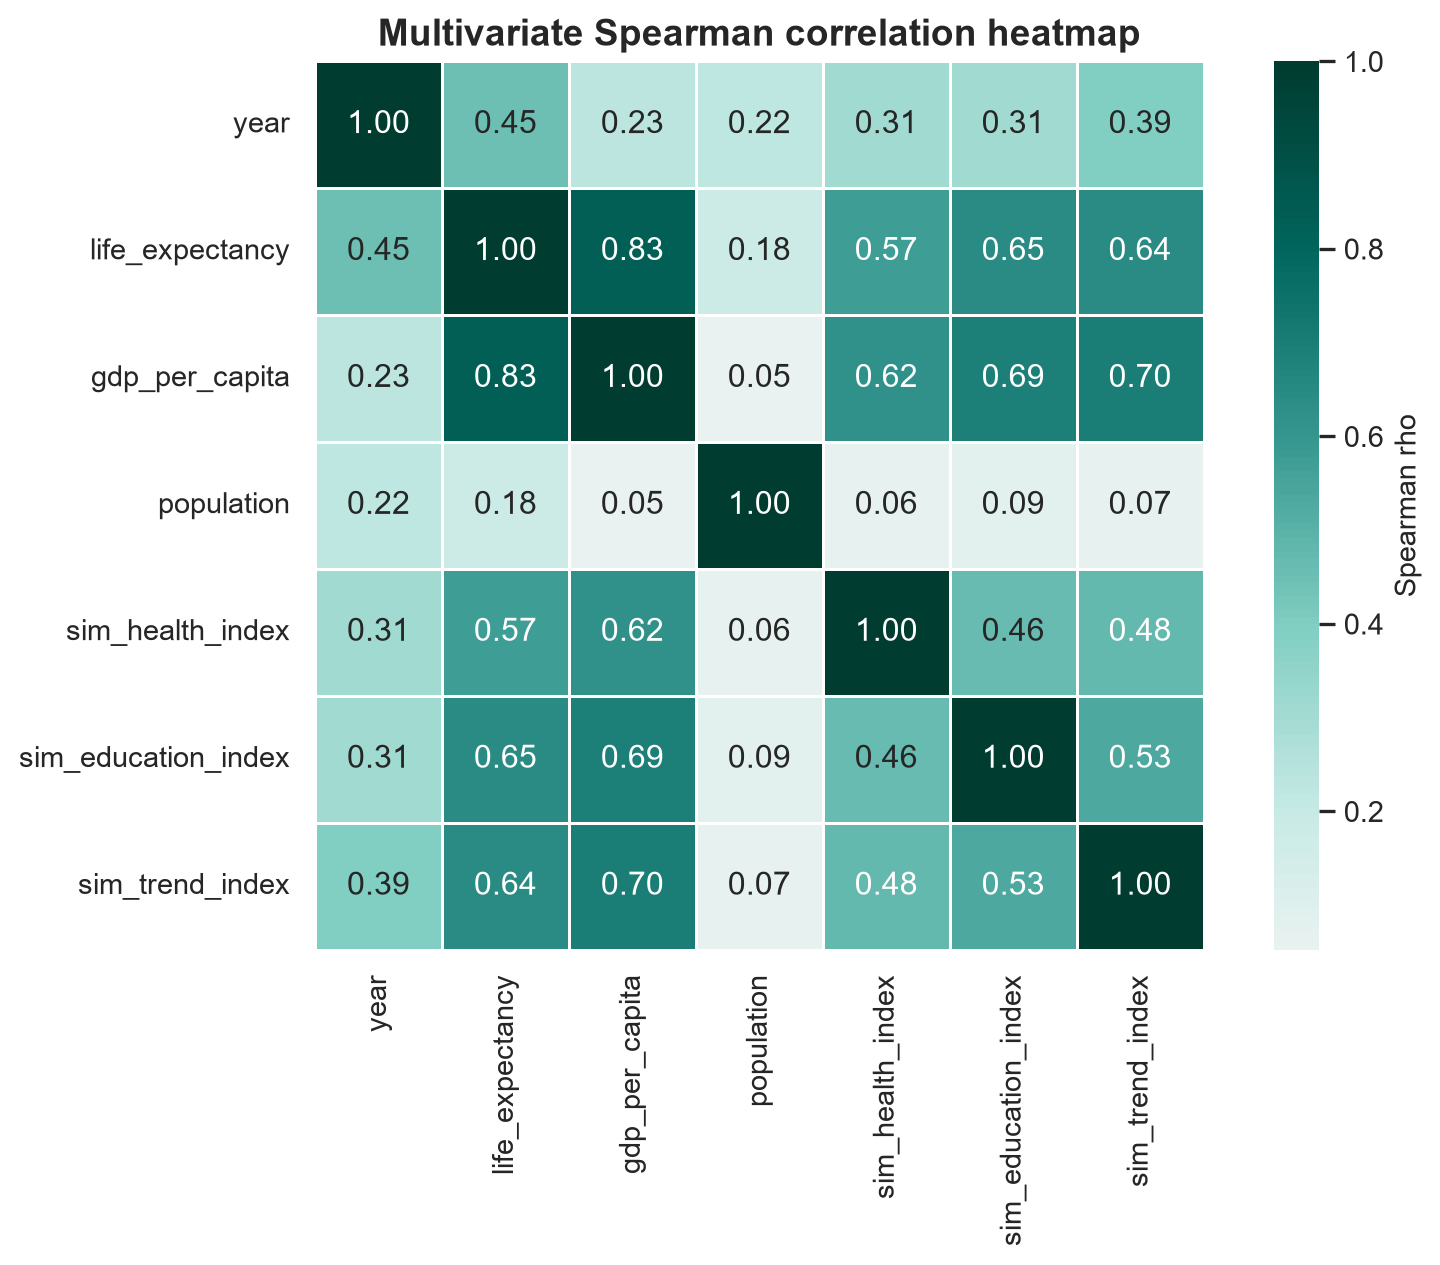

In [9]:
display(Image(filename=str(ROOT/"charts/06_correlation_heatmap.png"),width=760))

**SO WHAT?** Tương quan Spearman giữa GDP/người và tuổi thọ khoảng **0,8265** (dương mạnh), nhưng không chứng minh GDP làm tăng tuổi thọ. Các chỉ số `sim_*` được sinh một phần từ GDP và năm, nên sự liên hệ của chúng với tuổi thọ không phải khám phá quan hệ y tế/xã hội độc lập. Vì vậy cần diễn giải chúng là biến mô phỏng minh họa và tránh khuyến nghị chính sách nhân quả.

#### 07 gdp lifeexp scatter

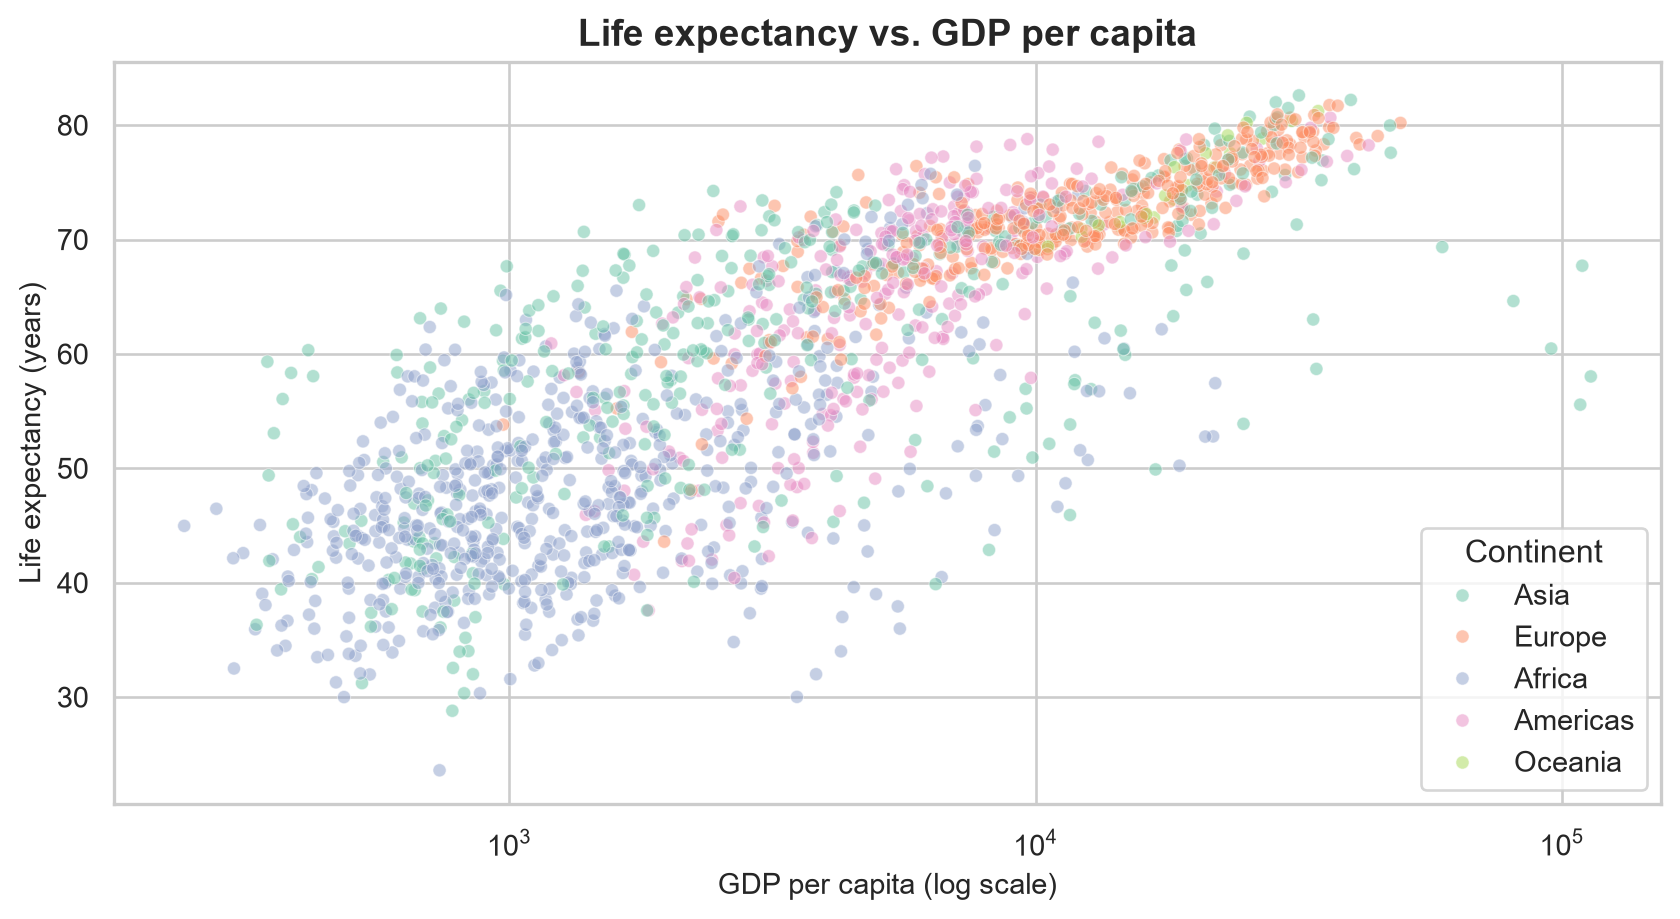

In [10]:
display(Image(filename=str(ROOT/"charts/07_gdp_lifeexp_scatter.png"),width=760))

**SO WHAT?** Scatter cho thấy GDP/người cao thường đi kèm tuổi thọ lớn hơn, với độ phân tán đáng kể ở GDP thấp và khả năng quan hệ không tuyến tính trên trục GDP gốc. Nhóm dùng biến `log_gdp` và so sánh LinearRegression với DecisionTreeRegressor; biến số đơn lẻ không đủ để khẳng định nguyên nhân.

#### 08 continent lifeexp grouped box

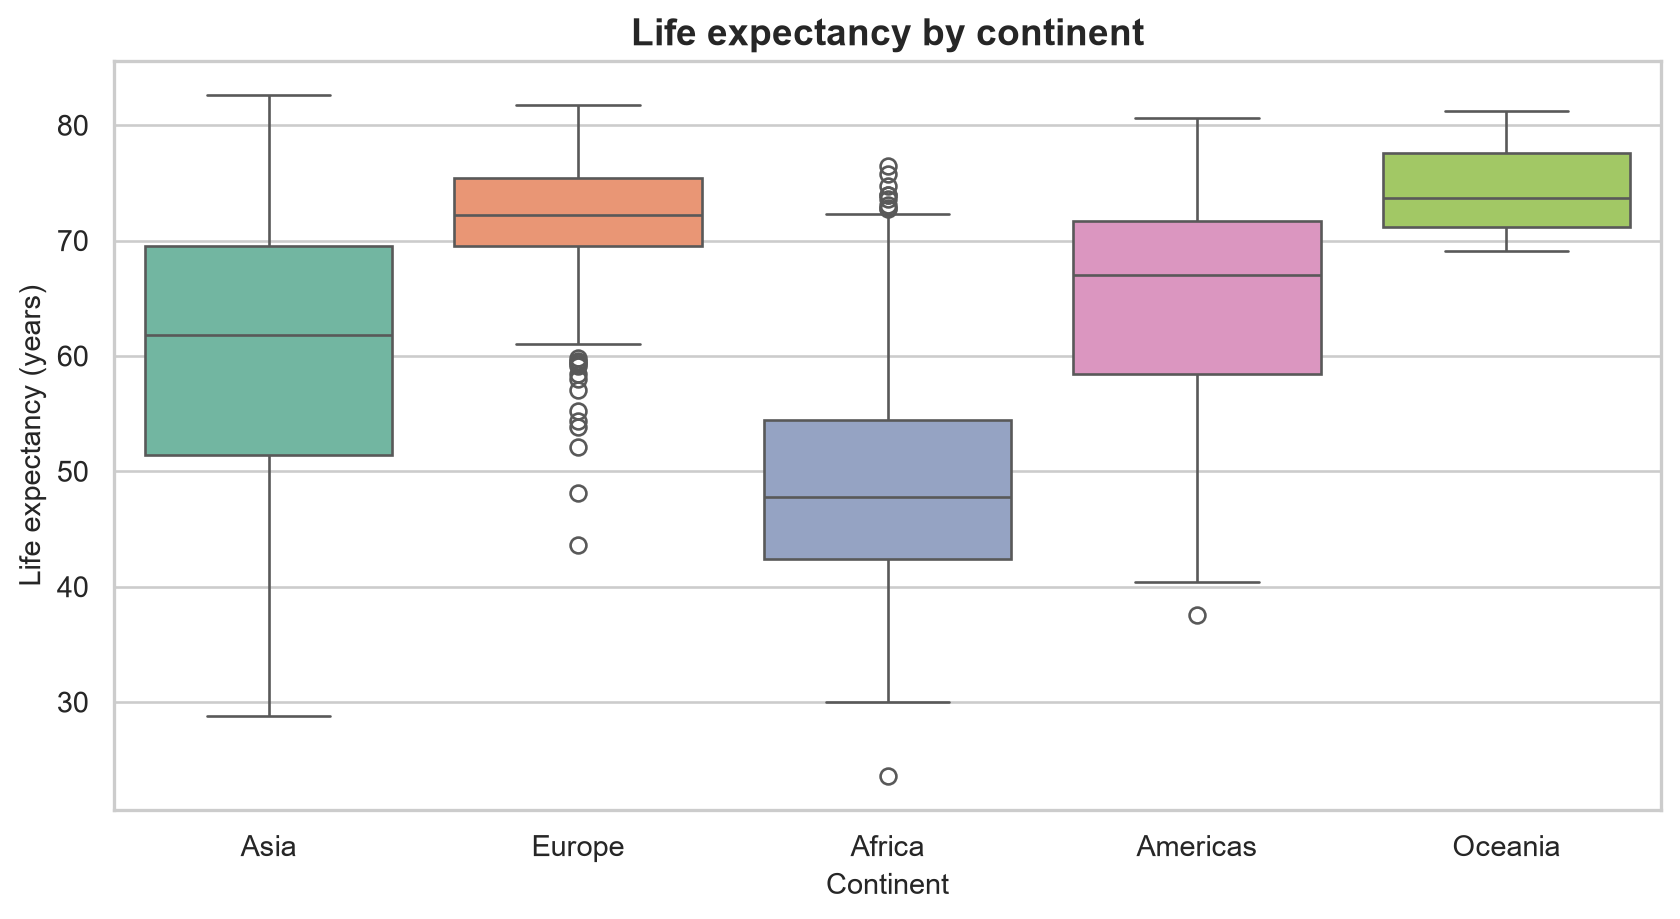

In [11]:
display(Image(filename=str(ROOT/"charts/08_continent_lifeexp_grouped_box.png"),width=760))

**SO WHAT?** Box plot cho thấy trung vị và độ phân tán tuổi thọ khác nhau theo châu lục. Vì vậy `continent` được xử lý như đặc trưng phân loại (`OneHotEncoder`) khi dự đoán. Tuy nhiên, khác biệt này có thể phản ánh nhiều yếu tố lịch sử; không diễn giải châu lục như quan hệ nhân quả hoặc đặc điểm của từng cá nhân.

#### 09 continent lifeexp stacked bar

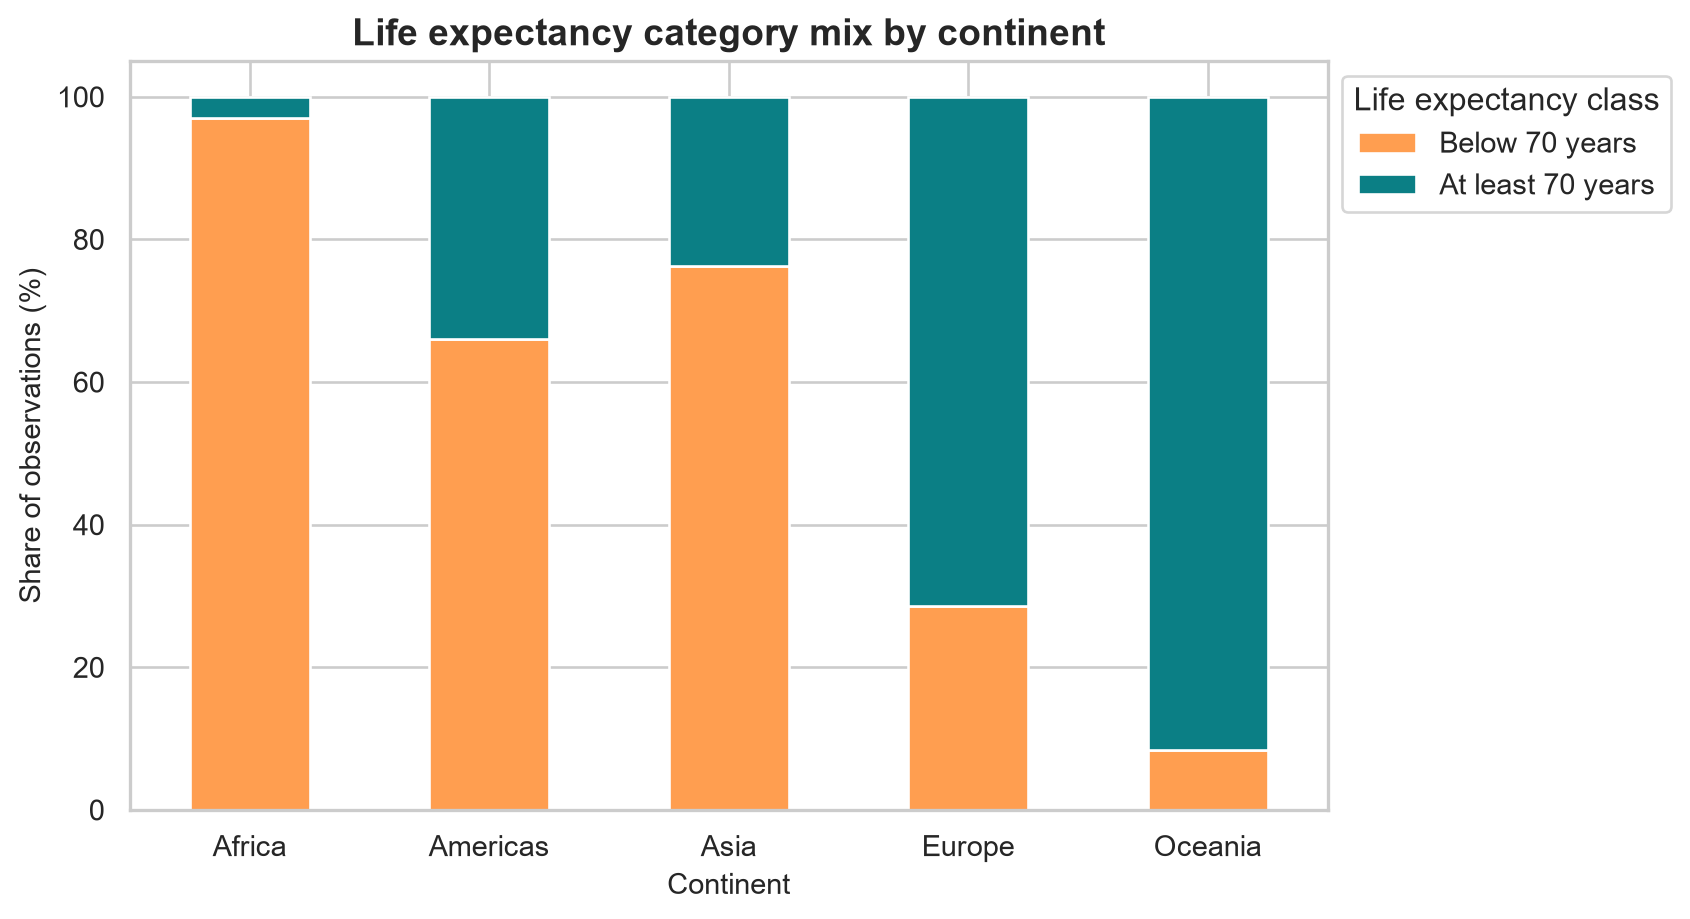

In [12]:
display(Image(filename=str(ROOT/"charts/09_continent_lifeexp_stacked_bar.png"),width=760))

**SO WHAT?** Tỉ trọng quan sát có tuổi thọ **≥ 70 năm** khác nhau giữa các châu lục. Nhãn này được tạo từ tuổi thọ quan sát gốc, là mục tiêu phân loại nhị phân. Mô hình phải xem phân bố lớp trong tập train và ưu tiên **F1 macro, precision, recall và confusion matrix**, không chỉ accuracy.

#### 10 historical trend

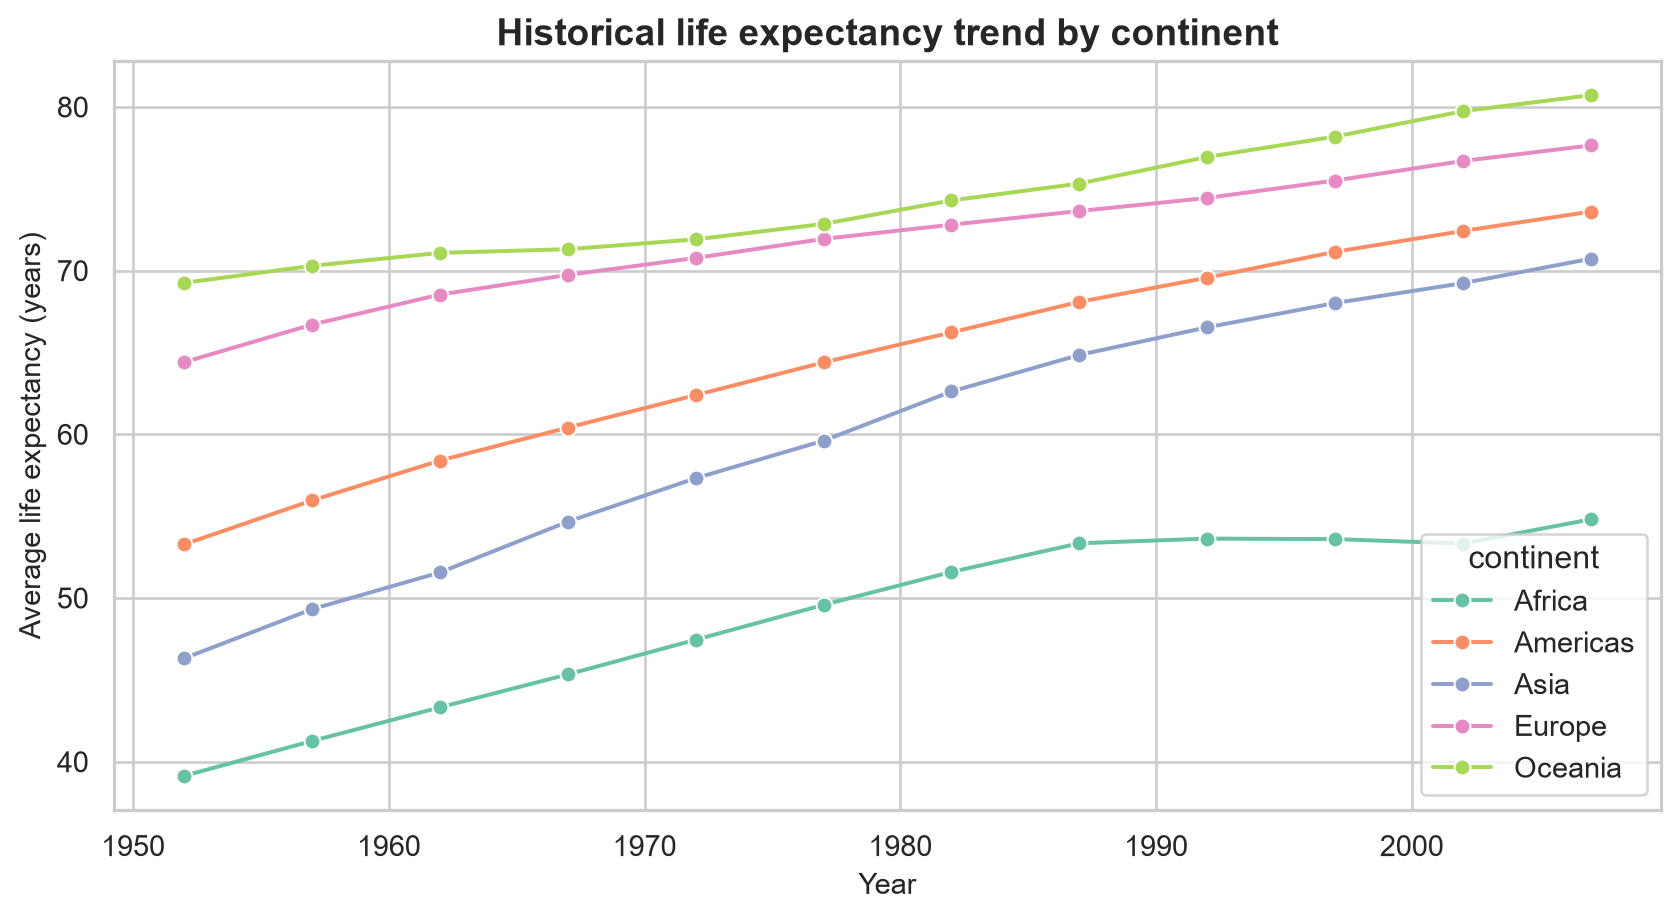

In [13]:
display(Image(filename=str(ROOT/"charts/10_historical_trend.png"),width=760))

**SO WHAT?** Đường trung bình tuổi thọ cho thấy tiến trình lịch sử khác nhau theo châu lục từ **1952 đến 2007**. Năm là một đặc trưng quan trọng, nhưng do nguồn kết thúc năm 2007, giao diện cũng giới hạn đúng thời kỳ này. Mô hình **không** phải dự báo năm 2026 và cần dữ liệu quan trắc mới để đưa ra nhận định hiện tại.

### 4. Kiểm chứng tích hợp **hai nguồn dữ liệu thực** (Gapminder + World Bank)

**Các script:** `09_standardize_worldbank.py` → `10_compare_sources.py` → `11_concat_two_sources.py` → `12_merge_multisource_dynamic.py` → `13_fill_missing_lifeexp.py` → `14_clean_multisource.py`.

- Đầu vào thực: Gapminder **1.704** bản ghi và World Bank **1.400** bản ghi cùng phạm vi quốc gia/năm. Chọn World Bank chỉ tiêu tuổi thọ **SP.DYN.LE00.IN**, chuẩn hóa mã `PRK` của Triều Tiên (dữ liệu Gapminder gốc có lỗi ISO `KOR`), giữ riêng bản dữ liệu gốc.
- `pd.concat` nối dọc hai bảng đã đồng bộ; giữ cột `data_source` để phân biệt xuất xứ. Tổng **3.104 dòng theo nguồn** nhưng chỉ **1.704 quốc gia–năm duy nhất**; các quan sát trùng thời điểm ở 2 nguồn **không phải 2 mẫu độc lập**.
- `pd.merge` Left Join ghép theo cặp ISO–năm và `record_id` để giữ toàn bộ bản ghi theo nguồn, bổ sung thông tin kinh tế từ Gapminder và các chỉ số động **mô phỏng**. World Bank **không** trực tiếp cung cấp các cột GDP, dân số hay `sim_*` trong nhánh này.
- World Bank thiếu **6** giá trị tuổi thọ; bù bằng Gapminder đúng cặp quốc gia–năm và gắn cờ `life_expectancy_imputed=True`, nguồn `Gapminder fallback`.
- **690** ô thiếu trong 4 cột `sim_*` của bảng 3.104 dòng được bù theo quy trình có kiểm toán; sau bù **0** ô thiếu. Nhiều ô mô phỏng là bản lặp theo nguồn chứ không phải quan sát độc lập.
- So sánh 1.394 cặp tuổi thọ hợp lệ giữa hai nguồn cho thấy sai khác tuyệt đối trung bình **~1,795 năm** và **113** cặp khác nhau trên 5 năm; không tự động coi hai nguồn hoán đổi tương đương.

**Lưu ý để tái lập:** Các tệp `data/raw/worldbank_life_expectancy.json` và toàn bộ `src/09` đến `src/14` phải nằm trong project. Chạy code bên dưới sẽ **tạo lại riêng nhánh đa nguồn** nhưng không ghi đè `master_clean.csv` và các mô hình Stage 2.

In [14]:
# SOURCE 1: https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv
# SOURCE 2: https://api.worldbank.org/v2/country/all/indicator/SP.DYN.LE00.IN?format=json&per_page=20000
# Tái lập nhánh đa nguồn, tách biệt bộ dữ liệu huấn luyện AI 1.704 dòng.
for script in [
    '09_standardize_worldbank.py',
    '10_compare_sources.py',
    '11_concat_two_sources.py',
    '12_merge_multisource_dynamic.py',
    '13_fill_missing_lifeexp.py',
    '14_clean_multisource.py',
]:
    process = subprocess.run([sys.executable, str(ROOT/'src'/script)], cwd=ROOT,
                             capture_output=True, text=True)
    print(f'{script}: exit={process.returncode}')
    if process.returncode != 0:
        print(process.stdout)
        print(process.stderr)
        raise RuntimeError(f'Script lỗi: {script}')

multi = pd.read_csv(ROOT/'data/processed/multisource_clean.csv')
assert len(multi)==3104 and multi.record_id.nunique()==1704
assert multi.isna().sum().sum()==0
assert not multi.duplicated(['data_source','iso_alpha','year']).any()
print('MULTISOURCE VALIDATION PASS:',len(multi),'source-rows;',multi.record_id.nunique(),'country-years')
display(pd.read_csv(ROOT/'reports/multisource_audit.csv'))
display(pd.read_csv(ROOT/'reports/multisource_imputation_report.csv'))
display(pd.read_csv(ROOT/'reports/multisource_distribution_impact.csv'))

09_standardize_worldbank.py: exit=0
10_compare_sources.py: exit=0
11_concat_two_sources.py: exit=0
12_merge_multisource_dynamic.py: exit=0
13_fill_missing_lifeexp.py: exit=0
14_clean_multisource.py: exit=0
MULTISOURCE VALIDATION PASS: 3104 source-rows; 1704 country-years


,data_source,records,countries,missing_life_exp
0,Gapminder,1704,142,0
1,World Bank,1400,140,6


,column,missing_before,missing_after,filled_count
0,sim_health_index,174,0,174
1,sim_education_index,224,0,224
2,sim_trend_index,139,0,139
3,sim_policy_group,153,0,153


,column,mean_before,mean_after,median_before,median_after,std_before,std_after
0,sim_health_index,71.951416,71.887512,71.975,71.670,14.239334,13.890626
1,sim_education_index,72.536713,72.502488,72.780,72.465,13.679893,13.303736
2,sim_trend_index,73.943473,73.809636,73.620,73.515,12.977124,13.049568


## PHẦN II — GIAI ĐOẠN 2
### 4. PCA, K-Means, Regression, Classification

Chuẩn hóa trước PCA; chọn số PCs ít nhất đạt 90% phương sai trong khoảng 85–95%. K-Means K=2..8 có Elbow WCSS và Silhouette trên hai biểu diễn. Học có giám sát chia **theo quốc gia** để country không xuất hiện cả train và test.

In [15]:
subprocess.run([sys.executable,str(ROOT/'src/03_model_stage2.py')],cwd=ROOT,check=True)
metrics=json.loads((ROOT/'reports/model_results.json').read_text())
print(json.dumps(metrics,indent=2,ensure_ascii=False))
display(pd.read_csv(ROOT/'reports/kmeans_k_benchmark.csv').head(10))
display(pd.read_csv(ROOT/'reports/regression_benchmark.csv'))
display(pd.read_csv(ROOT/'reports/classification_benchmark.csv'))

{
  "pca_components": 7,
  "explained_variance": 0.9125601865438817,
  "chosen_k": 2,
  "cluster_representation": "PCA features",
  "winning_silhouette": 0.2881036921435017,
  "original_same_k_silhouette": 0.2638598625167073,
  "pca_same_k_silhouette": 0.2881036921435017,
  "train_rows": 1356,
  "test_rows": 348,
  "train_countries": 113,
  "test_countries": 29,
  "class_train_distribution": {
    "0": 0.7065,
    "1": 0.2935
  },
  "class_weight": "balanced",
  "winning_regression": "LinearRegression",
  "winning_classification": "LogisticRegression",
  "best_regression": {
    "MSE": 38.05606,
    "RMSE": 6.16896,
    "R2": 0.77824
  },
  "best_classification": {
    "Accuracy": 0.87069,
    "Precision_macro": 0.83322,
    "Recall_macro": 0.86235,
    "F1_macro": 0.84529,
    "F1_positive": 0.78261
  }
}


,representation,k,wcss,silhouette
0,Original features,2,8672.859079,0.263860
1,PCA features,2,7578.382915,0.288104
2,Original features,3,7801.088901,0.192546
3,PCA features,3,6708.322098,0.219184
4,Original features,4,7022.323424,0.176865
5,PCA features,4,5935.691280,0.201662
6,Original features,5,6584.709432,0.167046
7,PCA features,5,5504.299736,0.191664
8,Original features,6,6233.125266,0.162872
9,PCA features,6,5161.824735,0.188289


,algorithm,MSE,RMSE,R2
0,LinearRegression,38.056059,6.168959,0.778236
1,DecisionTreeRegressor,45.290828,6.729846,0.736077


,algorithm,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_positive
0,LogisticRegression,0.870690,0.833219,0.862351,0.845292,0.782609
1,DecisionTreeClassifier,0.850575,0.810185,0.832341,0.819703,0.745098


#### 11 pca cumulative variance

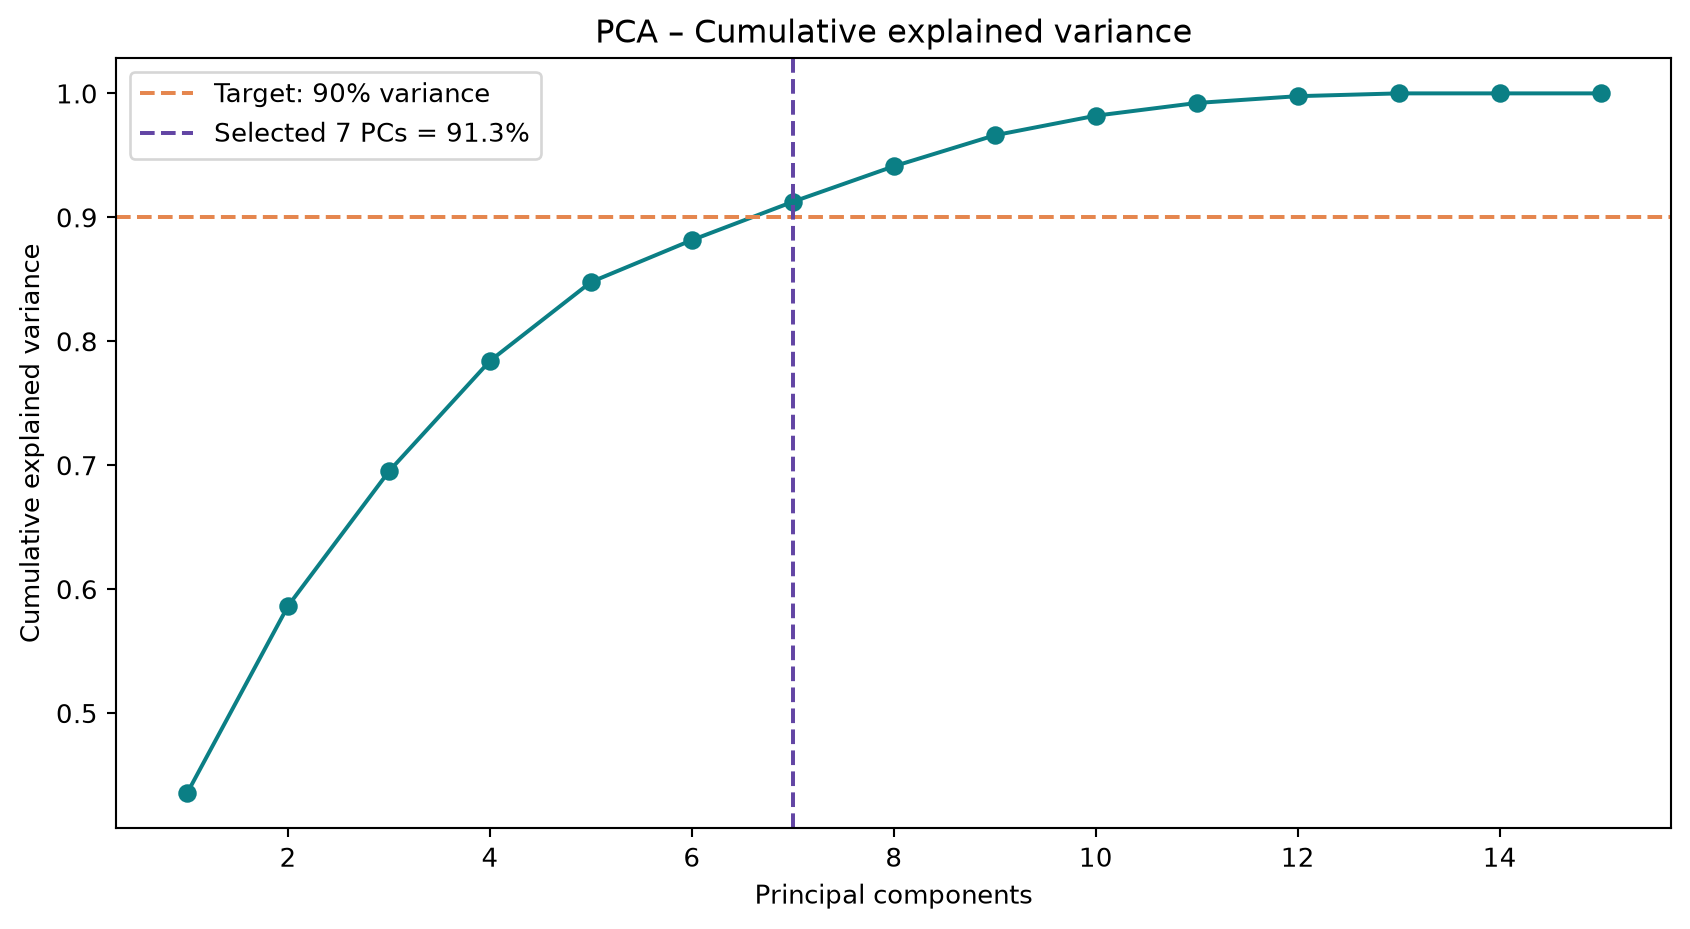

In [16]:
display(Image(filename=str(ROOT/"charts/11_pca_cumulative_variance.png"),width=760))

**SO WHAT?** Chọn **7 principal components** giữ **91,256%** phương sai, nằm trong ngưỡng **85–95%** của đề bài. Dùng StandardScaler trước PCA và chọn số thành phần ít nhất vượt 90%. Bước này hỗ trợ giảm chiều để thử phân cụm; không có nghĩa 7 chiều giữ mọi thông tin hữu ích về các mục tiêu dự đoán.

#### 12 kmeans elbow silhouette

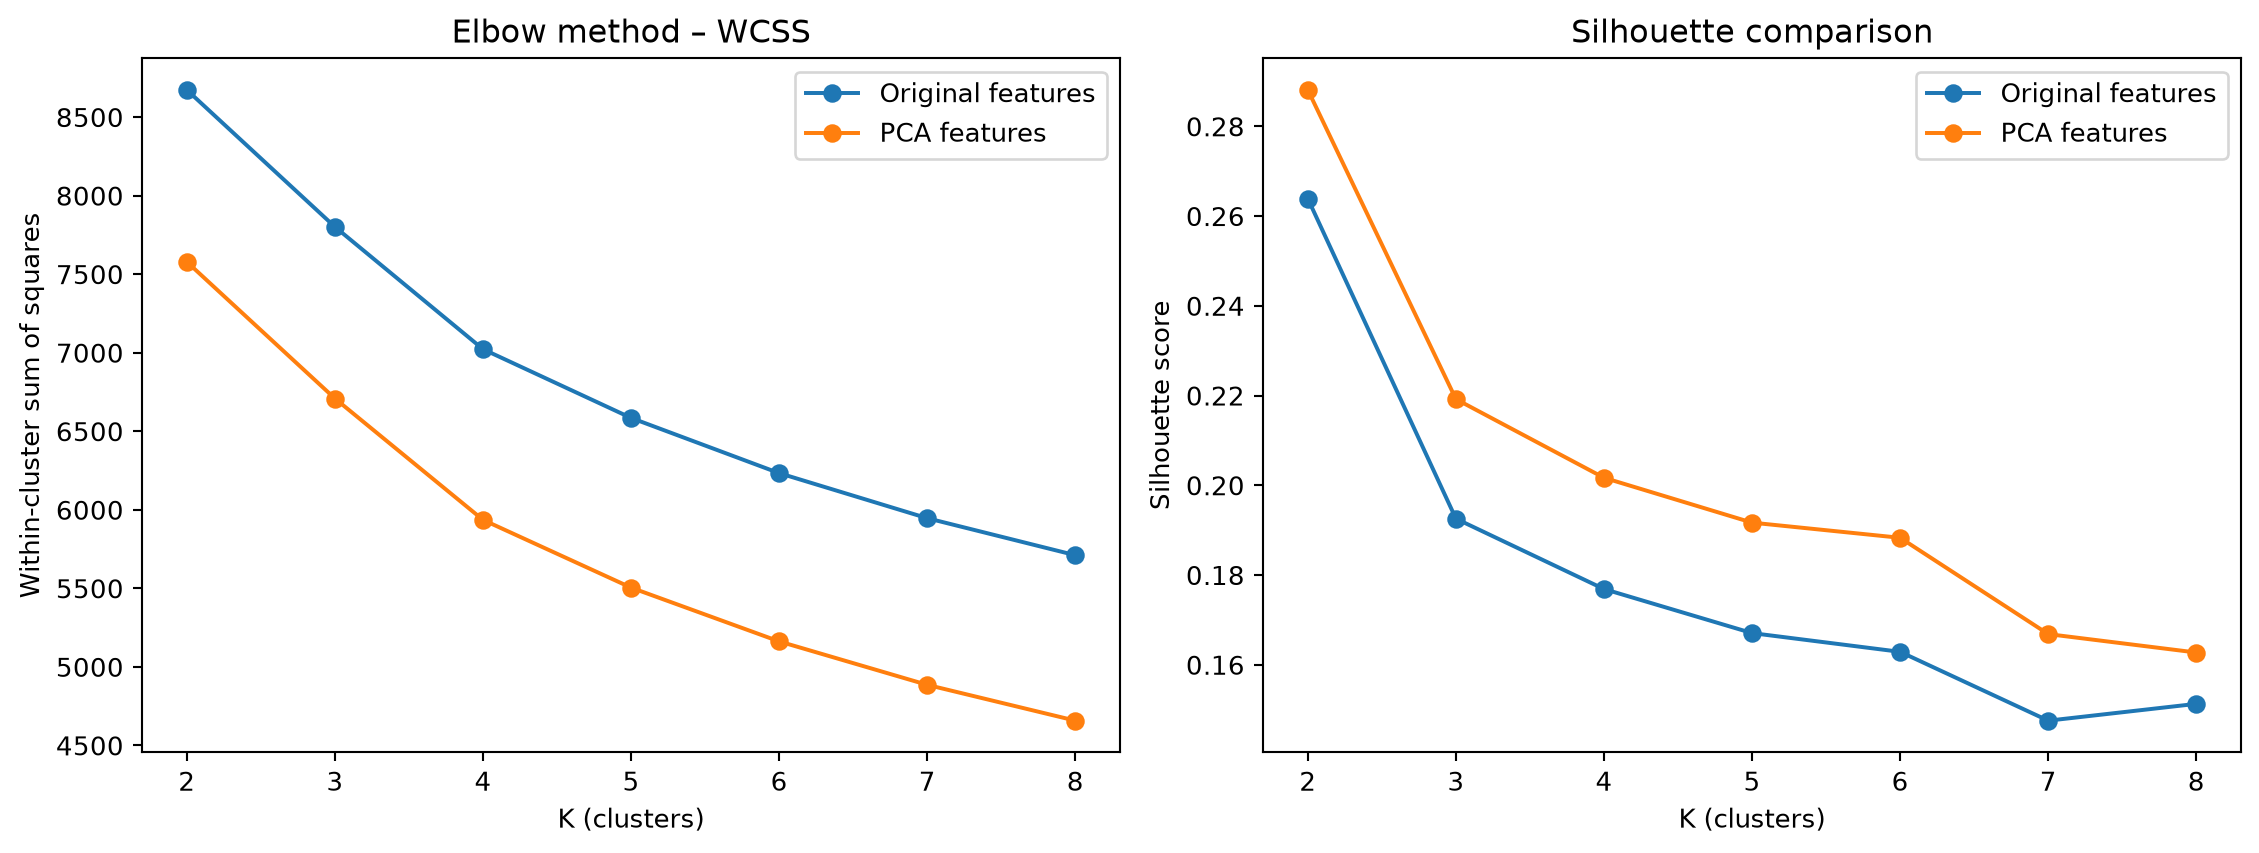

In [17]:
display(Image(filename=str(ROOT/"charts/12_kmeans_elbow_silhouette.png"),width=760))

**SO WHAT?** Với cùng **K=2**, Silhouette PCA **0,2881** so với đặc trưng chưa giảm chiều **0,2639**. Nhóm chọn 2 cụm do kết quả so sánh WCSS/Silhouette, song **Silhouette khoảng 0,29 là mức phân tách chưa mạnh**. Nhãn cụm chỉ là phân đoạn kỹ thuật trên quốc gia–năm lịch sử, không mặc nhiên là nhóm tự nhiên hoặc xếp hạng chất lượng quốc gia.

#### 13 kmeans 2d clusters

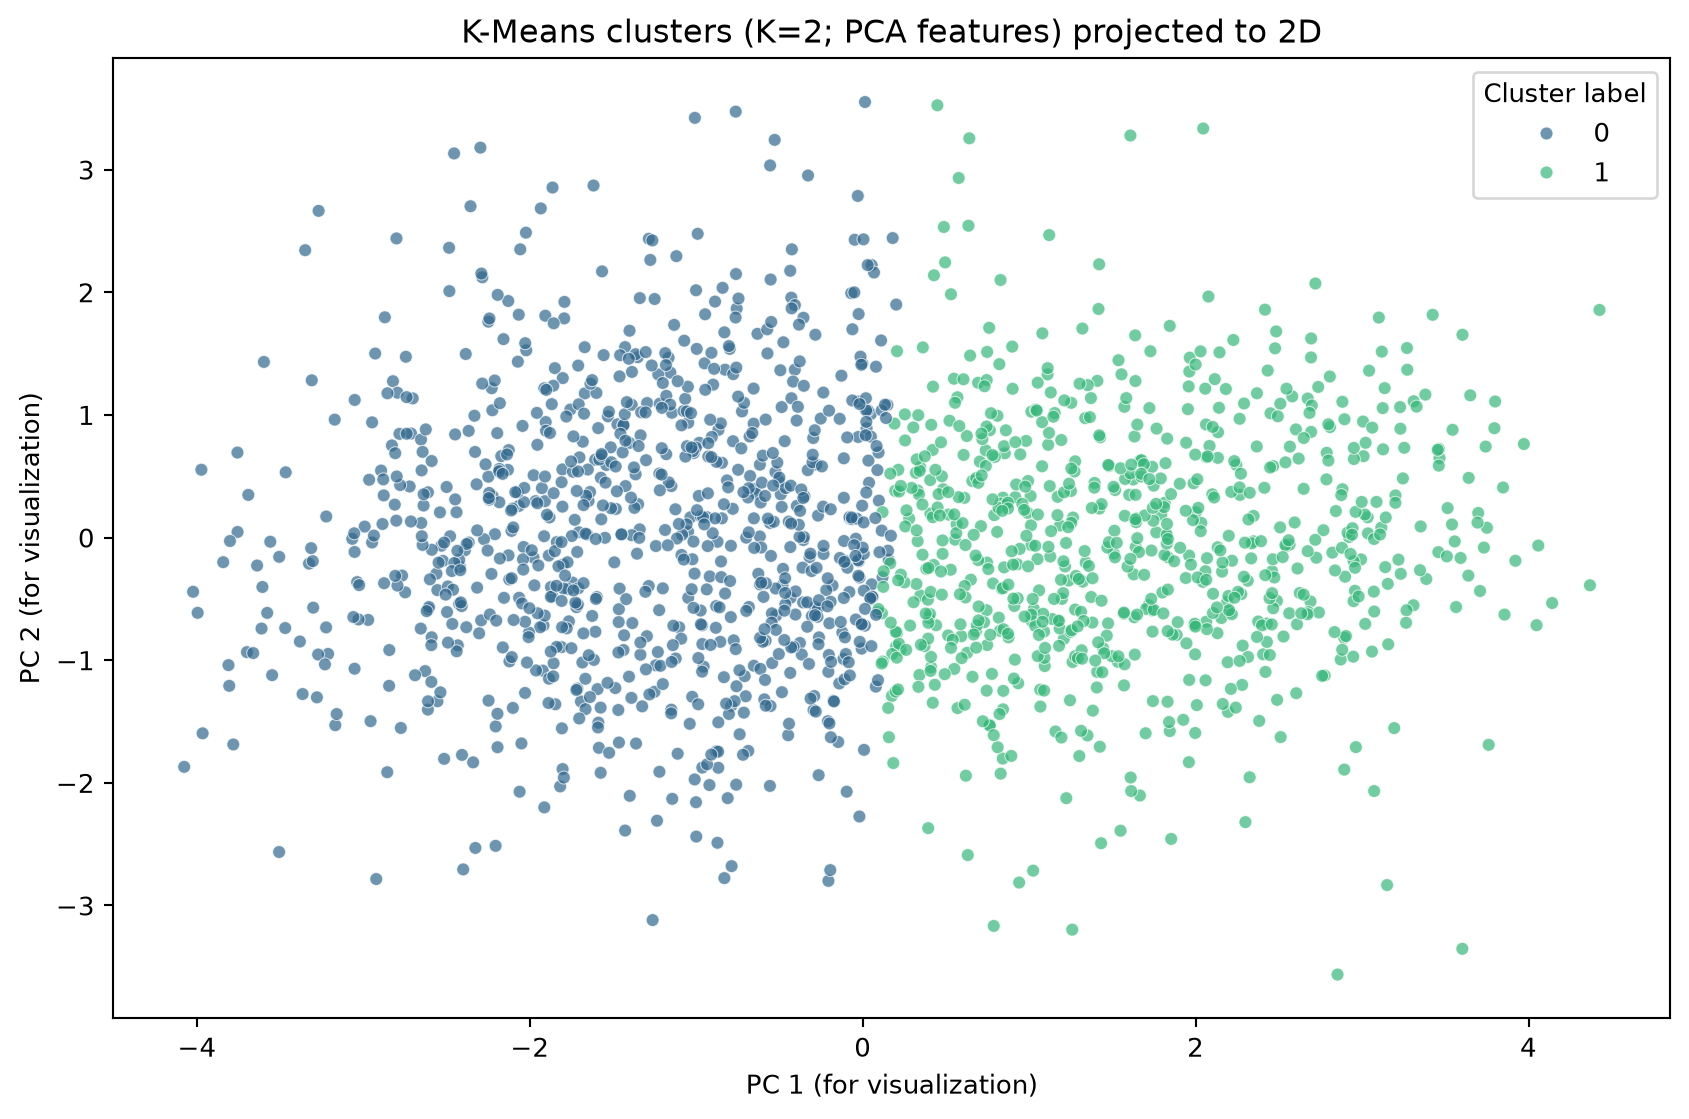

In [18]:
display(Image(filename=str(ROOT/"charts/13_kmeans_2d_clusters.png"),width=760))

**SO WHAT?** Biểu đồ PC1–PC2 hiển thị hai cụm với màu nhãn khác nhau; đây chỉ là **phép chiếu 2D** nên các điểm chồng nhau không nhất thiết chứng tỏ mô hình phân cụm sai. Nhãn đã lưu vào `master_with_clusters.csv` và SQLite; có thể so sánh hồ sơ cụm qua GDP trung vị và tuổi thọ trung bình mà không sử dụng nhãn như đánh giá chính sách.

#### 14 regression actual vs predicted

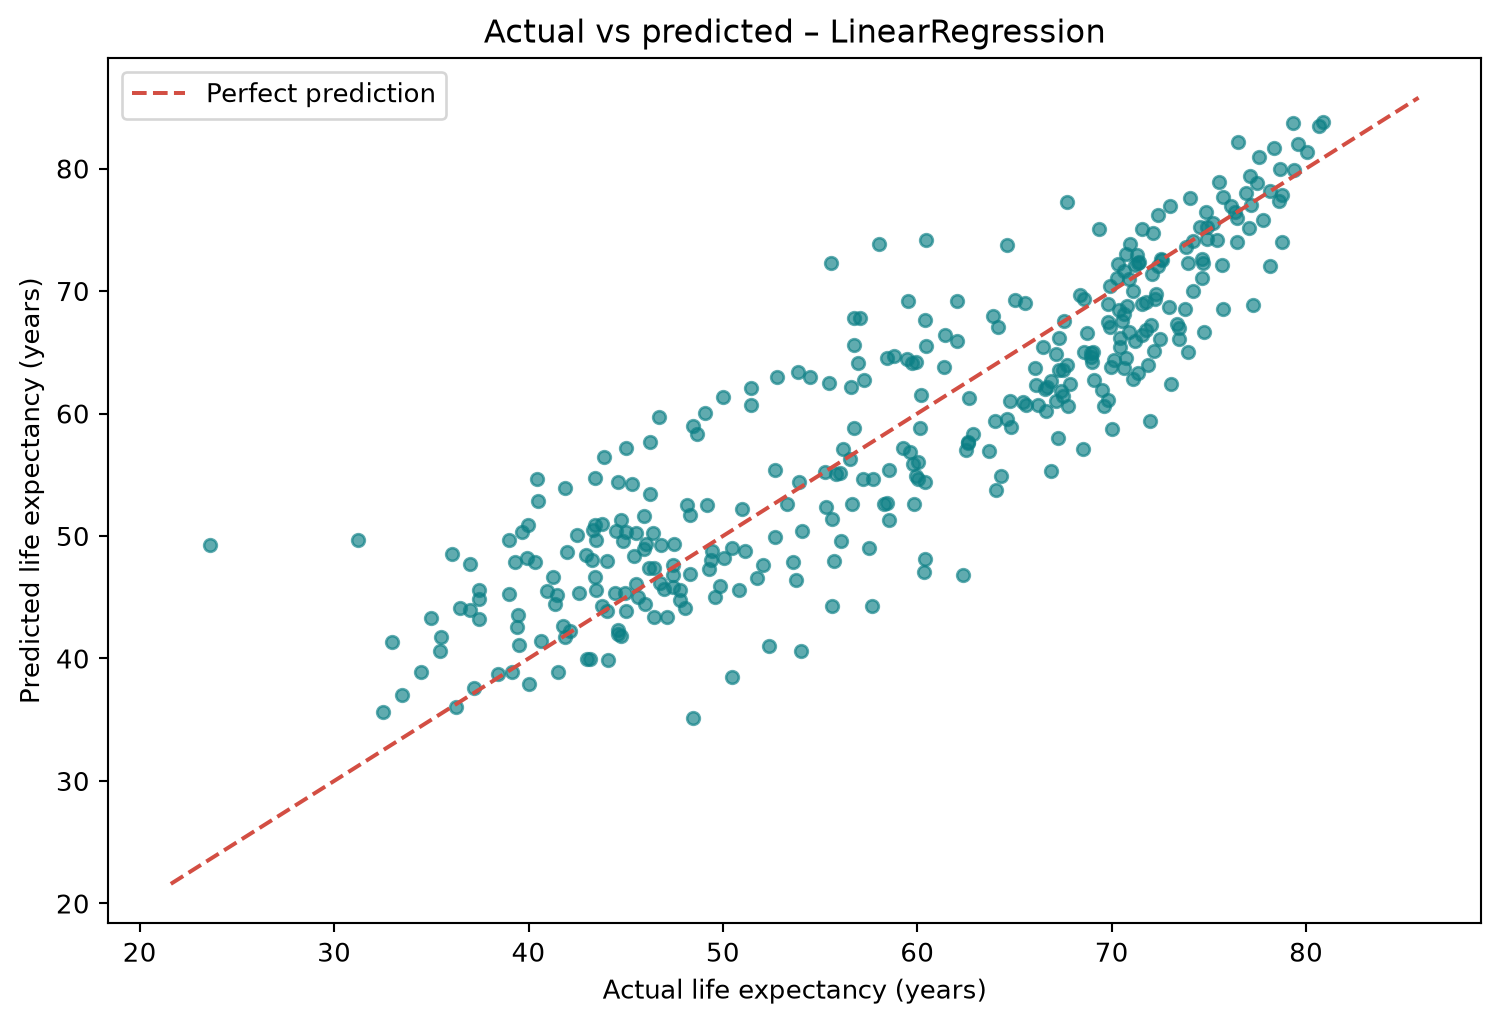

In [19]:
display(Image(filename=str(ROOT/"charts/14_regression_actual_vs_predicted.png"),width=760))

**SO WHAT?** Trên tập kiểm tra gồm **29 quốc gia chưa xuất hiện trong train (348 hàng)**, **LinearRegression** đạt RMSE **6,169 năm**, R² **0,778**, tốt hơn **DecisionTreeRegressor** (RMSE **6,730**, R² **0,736**). Vì RMSE vẫn đáng kể với một mục tiêu có giá trị vài chục năm, dự đoán chỉ nên xem là minh họa, không dùng cho quyết định thực tế.

#### 15 regression residual plot

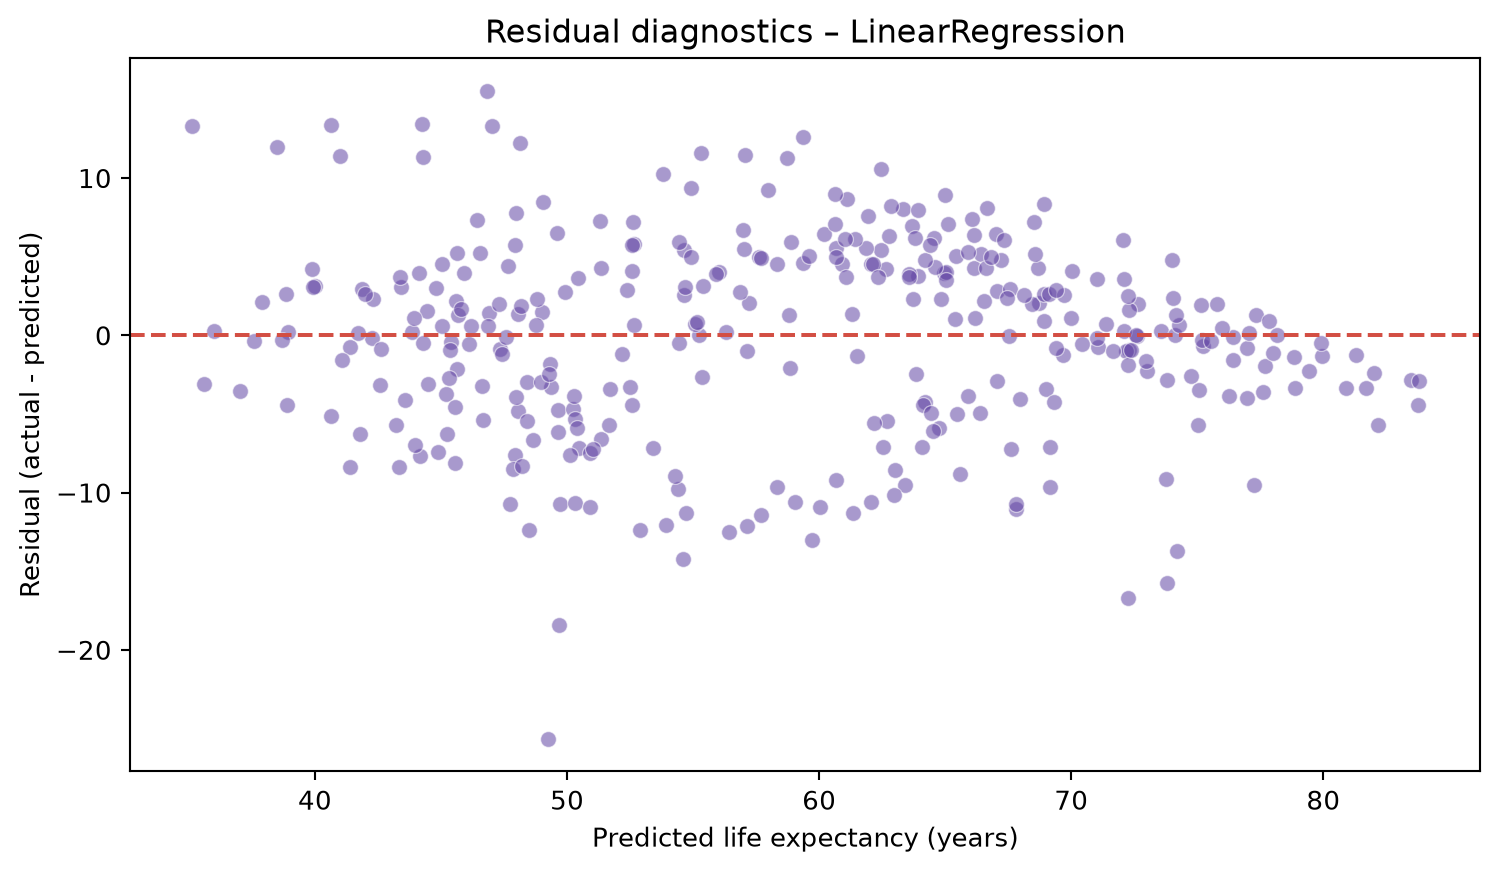

In [20]:
display(Image(filename=str(ROOT/"charts/15_regression_residual_plot.png"),width=760))

**SO WHAT?** Biểu đồ phần dư (giá trị thật trừ dự đoán) giúp kiểm tra mô hình có thiên lệch theo vùng giá trị dự đoán hay không. Điểm nằm lệch khỏi đường phần dư 0 biểu thị sai số. Nếu có cấu trúc hoặc độ phân tán thay đổi theo mức dự đoán, có thể bổ sung đặc trưng hoặc thử mô hình khác; không được kết luận mô hình hoàn hảo chỉ dựa trên R².

#### 16 confusion matrix

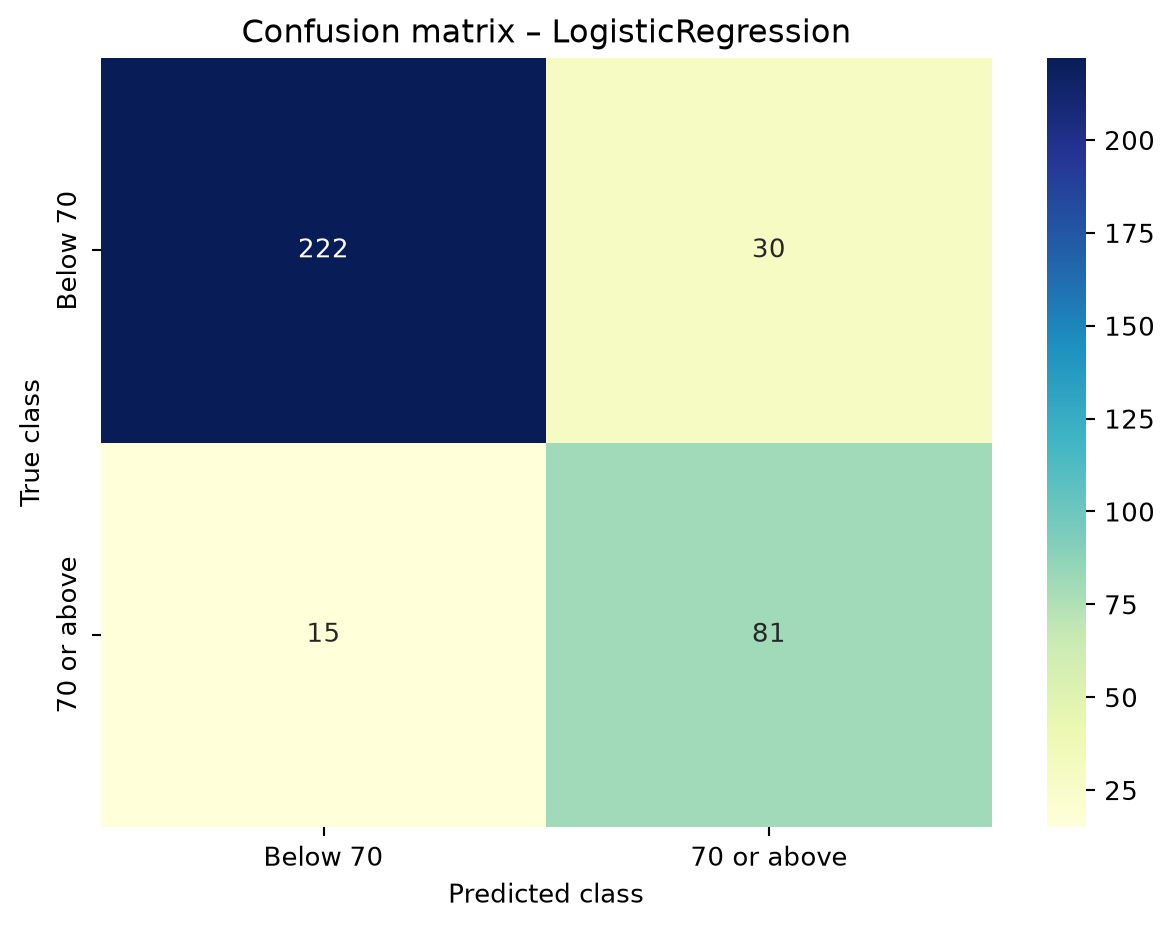

In [21]:
display(Image(filename=str(ROOT/"charts/16_confusion_matrix.png"),width=760))

**SO WHAT?** **LogisticRegression** đạt Accuracy **87,07%**, F1 macro **0,8453** so với **DecisionTreeClassifier** F1 macro **0,8197**. Ma trận nhầm lẫn gồm **222 TN, 30 FP, 15 FN, 81 TP**; có cả hai loại sai sót. Do tỉ lệ nhãn ≥70 năm không cân bằng, nhóm dùng `class_weight='balanced'` và báo cáo F1 macro bên cạnh precision/recall, thay vì chỉ nhìn accuracy.

### 5. Database, triển khai Gradio và bằng chứng chạy thực tế

- **SQLite:** Đã ghi các bảng `master_sparse`, `master_clean`, `master_with_clusters` và đọc ngược về Python.
- **ChromaDB:** Đã chạy thành công qua `PersistentClient`, collection `country_year_embeddings` có **1.704 vector 7 chiều**, chứng thực bằng `reports/chroma_status.json` và ảnh `screenshots/05_Stage1_ChromaDB_Success.png`.
- **Gradio:** Đã chạy trên máy Windows và có ảnh thực tế của tab dự đoán, trực quan hóa, benchmark, nguồn dữ liệu trong `screenshots/`.
- Hai database và UI vẫn hoạt động trên nhánh dữ liệu AI Gapminder **1.704** dòng. Nhánh World Bank **3.104** dòng dùng để tích hợp và kiểm tra nguồn riêng, **không** được mô tả là dữ liệu đã dùng huấn luyện."

In [22]:
import sqlite3
with sqlite3.connect(ROOT/'databases/gapminder_project.sqlite') as c:
    print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'",c))
    print(pd.read_sql('SELECT COUNT(*) as n FROM master_with_clusters',c))
print('For vector DB run: python src/04_chromadb_vector.py')
print('For web UI run: python ui/app.py')

                   name
0         master_sparse
1          master_clean
2  master_with_clusters
      n
0  1704
For vector DB run: python src/04_chromadb_vector.py
For web UI run: python ui/app.py


**Ba khuyến nghị dựa trên quan sát; không phải kết luận nhân quả:**

1. **Ưu tiên nghiên cứu bổ sung cho nhóm quốc gia–năm có GDP lịch sử thấp:** Cụm 0 có GDP/người trung vị **~1.368 USD** và tuổi thọ trung bình **~50,86 năm**, thấp hơn cụm 1 (**~9.867 USD; ~69,85 năm**). Cần thêm các chỉ số y tế–giáo dục quan sát thật trước khi xây dựng chương trình can thiệp.
2. **Giữ hồi quy tuyến tính làm baseline:** RMSE **6,17 năm** so với cây **6,73 năm**; nên phân tích sai số theo vùng/năm và tăng chất lượng biến quan sát trước ứng dụng.
3. **Dùng F1 macro và xác suất khi diễn giải phân loại:** Logistic Regression F1 macro **0,845** tốt hơn Decision Tree **0,820**; xác suất dự đoán phải đi kèm điều kiện lịch sử và giới hạn của dữ liệu mô phỏng.

**Giới hạn:** Stage 2 huấn luyện trên **1.704 dòng Gapminder**, không phải **3.104 dòng tích hợp hai nguồn**. Hai nguồn có khác biệt giá trị tuổi thọ (MAE giữa nguồn ~1,795 năm với 1.394 cặp đầy đủ); không tùy tiện cộng đôi quan sát khi huấn luyện. Các chỉ số `sim_*` sinh bằng công thức từ GDP và năm, không phải dữ liệu độc lập về phát triển xã hội.

**Đã có bằng chứng:** ChromaDB chạy và ảnh Gradio đã được chụp trong project. **Bonus Web Crawling và LLM/Ollama** có mã nguồn nhưng chưa xác nhận có dataset chạy thực trong Notebook, nên không đánh dấu là hoàn thành cộng điểm.

**Trước khi nộp:** kiểm tra `README.md`, `requirements.txt`, báo cáo Word/PowerPoint và chạy `tests/test_pipeline.py` sau các lần sửa code. Nếu có thay đổi về dữ liệu AI, phải chạy lại Stage 2 và cập nhật metric."

### 6. Kiểm tra bằng chứng triển khai SQLite, ChromaDB và Gradio

**Không khởi động web server bên trong Notebook** (vì server Gradio chạy liên tục). Giao diện chạy bằng `python ui/app.py` và đã được chụp màn hình. Cell sau chỉ **đọc kiểm chứng** `chroma_status.json` và tên file trong `screenshots/`, không ghi đè database hoặc mô hình.

In [23]:
chroma_path = ROOT/'reports/chroma_status.json'
assert chroma_path.exists(), 'Thiếu reports/chroma_status.json; chạy python src/04_chromadb_vector.py'
chroma_result = json.loads(chroma_path.read_text(encoding='utf-8'))
print('ChromaDB:', chroma_result)
assert chroma_result.get('ingested') is True
assert chroma_result.get('count') == 1704
assert chroma_result.get('dimensions') == 7
screens = sorted((ROOT/'screenshots').glob('*.png'))
print('Screenshot files:',len(screens))
for img in screens:
    print('-',img.name)
assert any('ChromaDB' in s.name for s in screens), 'Thiếu ảnh kiểm chứng ChromaDB'
assert any('Du_doan' in s.name for s in screens), 'Thiếu ảnh dự đoán giao diện'
print('EVIDENCE CHECK PASS')

ChromaDB: {'ingested': True, 'backend': 'ChromaDB PersistentClient', 'collection': 'country_year_embeddings', 'count': 1704, 'dimensions': 7, 'probe_record': 'Afghanistan_1952', 'nearest_ids': ['Afghanistan_1952', 'Thailand_1952', 'Nepal_1957']}
Screenshot files: 7
- 01_UI_Du_doan_Asia.png
- 02_UI_Du_doan_Europe.png
- 02_UI_Truc_quan_hoa.png
- 03_UI_Ket_qua_danh_gia.png
- 04_UI_Nguon_du_lieu.png
- 05_Stage1_ChromaDB_Success.png
- 06_Stage1_Multisource_Validation.png
EVIDENCE CHECK PASS
